In [187]:
#Import section
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from downsampling import AntiAliasingFilter, gaindb

In [188]:
fs_hi = 44100
fs_low = fs_hi / 2
# numtaps = 255
numtaps = 513

In [189]:
filt = AntiAliasingFilter(fs_hi,fs_low, numtaps)

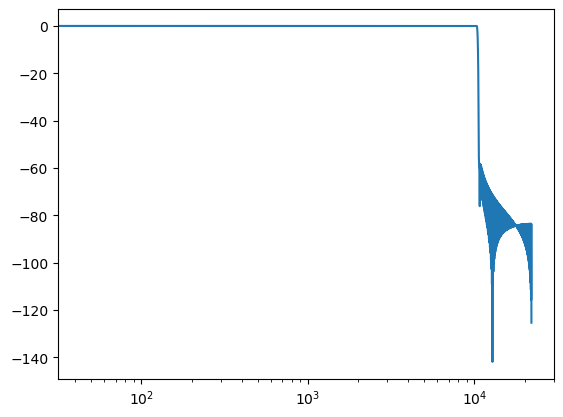

In [190]:
w, h = signal.freqz(filt, fs=fs_hi)
plt.semilogx(w,gaindb(np.abs(h)))

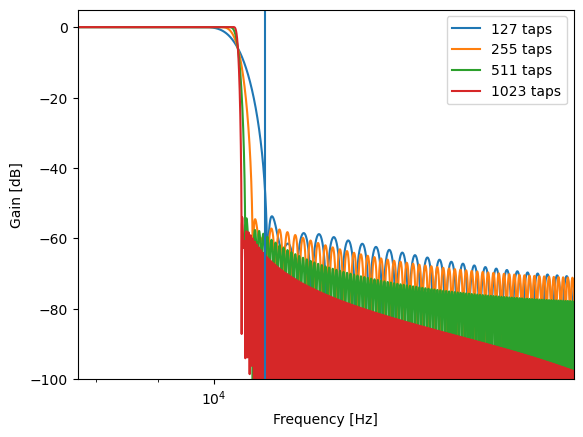

In [191]:

for numtaps in [127,255,511,1023]:
    filt = AntiAliasingFilter(fs_hi,fs_low, numtaps)

    w, h = signal.freqz(filt, fs=fs_hi, worN=44100)
    plt.semilogx(w,gaindb(np.abs(h)), label=f"{numtaps} taps")
    # print(len(filt))
plt.axvline(fs_low/2)
plt.xlim(0.7 * fs_low / 2, 1.8 * fs_low / 2)
plt.ylim(-100,5)
plt.legend()
plt.xlabel("Frequency [Hz]")
plt.ylabel("Gain [dB]")
plt.show()

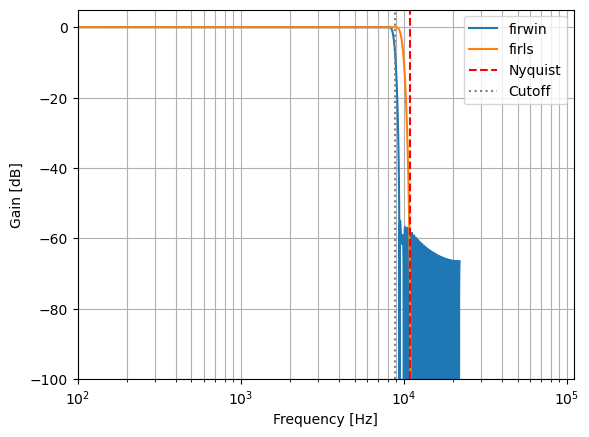

In [192]:
numtaps = 127
#numtaps = 63
cutoff_ratio = 0.80
ds_nyquist = fs_low / 2

#filt = AntiAliasingFilter(fs_hi,fs_low, numtaps, cutoff_ratio=cutoff_ratio)
filt = signal.firwin(numtaps,ds_nyquist*cutoff_ratio, fs=fs_hi)
w_win, h_win = signal.freqz(filt, fs=fs_hi, worN=44100)

filt = signal.firls(numtaps, bands=[0, ds_nyquist*cutoff_ratio, ds_nyquist, fs_hi / 2], desired=[1,1,0,0], weight=[0.1,0.9], fs=fs_hi)
w_ls, h_ls = signal.freqz(filt, fs=fs_hi, worN=44100)


plt.semilogx(w_win,gaindb(np.abs(h_win)), label=f"firwin")
plt.semilogx(w_ls,gaindb(np.abs(h_ls)), label=f"firls")
plt.axvline(ds_nyquist, color="red", linestyle="dashed", label="Nyquist")
plt.axvline(ds_nyquist*cutoff_ratio, color="grey", linestyle=":", label="Cutoff")
#plt.xlim(0.7 * fs_low / 2, 1.8 * fs_low / 2)
#plt.xlim(0.1 * fs_low / 2, 10 * fs_low / 2)
plt.xlim(100, 10 * fs_low / 2)
plt.ylim(-100,5)
plt.grid(True, "both")
plt.legend()
plt.xlabel("Frequency [Hz]")
plt.ylabel("Gain [dB]")
plt.show()

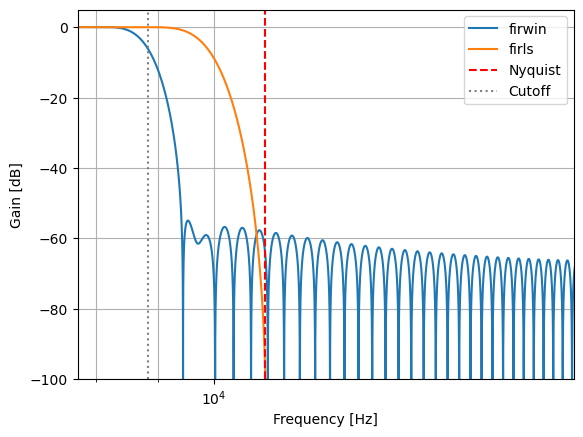

In [193]:
plt.semilogx(w_win,gaindb(np.abs(h_win)), label=f"firwin")
plt.semilogx(w_ls,gaindb(np.abs(h_ls)), label=f"firls")
plt.axvline(ds_nyquist, color="red", linestyle="dashed", label="Nyquist")
plt.axvline(ds_nyquist*cutoff_ratio, color="grey", linestyle=":", label="Cutoff")
plt.xlim(0.7 * fs_low / 2, 1.8 * fs_low / 2)
plt.ylim(-100,5)
plt.grid(True, "both")
plt.legend() 
plt.xlabel("Frequency [Hz]")
plt.ylabel("Gain [dB]")
plt.show()

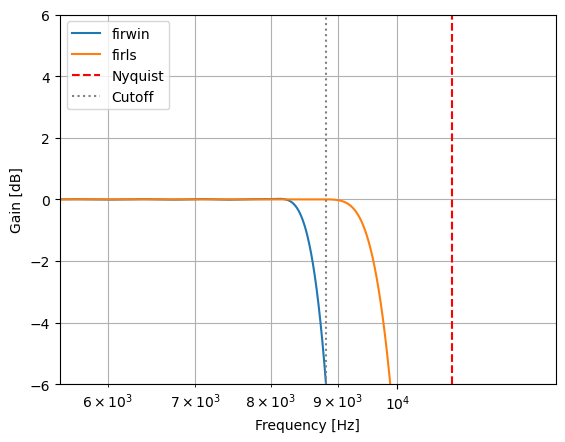

In [194]:
plt.semilogx(w_win,gaindb(np.abs(h_win)), label=f"firwin")
plt.semilogx(w_ls,gaindb(np.abs(h_ls)), label=f"firls")
plt.axvline(ds_nyquist, color="red", linestyle="dashed", label="Nyquist")
plt.axvline(ds_nyquist*cutoff_ratio, color="grey", linestyle=":", label="Cutoff")
plt.xlim(0.5 * fs_low / 2, 1.2 * fs_low / 2)
plt.ylim(-6,6)
plt.grid(True, "both")
plt.legend() 
plt.xlabel("Frequency [Hz]")
plt.ylabel("Gain [dB]")
plt.show()

In [195]:
print(f"LS NYQUIST ATTEN: {np.interp(ds_nyquist, w_ls, gaindb(np.abs(h_ls))):.4}dB")
print(f"WIN NYQUIST ATTEN: {np.interp(ds_nyquist, w_win, gaindb(np.abs(h_win))):.4}dB")

LS NYQUIST ATTEN: -94.49dB
WIN NYQUIST ATTEN: -63.3dB
